# Pneumonia Detection — SauberModel5 (224x224 + SE Attention + OneCycleLR)

SauberModel5 pushes the boundaries of the Inner Residual Inception architecture to achieve >95% accuracy.

### Key design changes vs SauberModel4
| Change | Rationale |
|---|---|
| Resolution 128x128 → **224x224** | Mandatory for fine-grained pulmonary textures |
| **Squeeze-and-Excitation (SE)** | Channel attention recalibrates feature importance |
| **OneCycleLR** | Dynamic learning rate escape loss plateaus |
| batch_size 128 → **64** | Balancing memory constraints at 224 resolution |

## Cell 1 — Imports & CUDA Verification

Imports all dependencies and verifies a CUDA GPU is available.  
`torch.backends.cudnn.benchmark = True` auto-selects the fastest cuDNN
convolution algorithm — essential now that we run 128×128 fixed inputs.

In [1]:
n_epoch =50
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import sys, os, time

if not torch.cuda.is_available():
    raise RuntimeError(
        f"CUDA not available (torch={torch.__version__}). "
        "Activate the project venv: .venv\\Scripts\\activate"
    )

# Let cuDNN benchmark and pick the fastest conv kernel for each shape
torch.backends.cudnn.benchmark = True

device = torch.device('cuda')
print(f'Device : {torch.cuda.get_device_name(0)}')
print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'Torch  : {torch.__version__}')
print(f'epochs  : {n_epoch}')

Device : NVIDIA GeForce RTX 4070 Ti SUPER
VRAM   : 17.2 GB
Torch  : 2.5.1+cu121
epochs  : 50


## Cell 2 — Dataset Download & Verification

The dataset is downloaded from Kaggle using the Kaggle API.  
- If `chest_xray/train` already exists the download **and** extraction are skipped entirely.
- We verify the file counts against the expected split sizes from the paper.

In [2]:
import zipfile, subprocess

os.environ['KAGGLE_USERNAME'] = "amrmsauber"
os.environ['KAGGLE_KEY']      = "KGAT_ceeffe620f713b8e6130fd931de9cb9c"
import kaggle

base_dir  = "chest_xray_ii"
zip_file  = "chest-xray-pneumonia.zip"
slug      = "paultimothymooney/chest-xray-pneumonia"

if not os.path.exists(base_dir):
    os.makedirs(base_dir, exist_ok=True)
    if not os.path.exists(zip_file):
        print("Downloading from Kaggle...")
        subprocess.run(f"kaggle datasets download -d {slug}", shell=True)

if not os.path.exists(os.path.join(base_dir, "train")):
    print("Extracting...")
    with zipfile.ZipFile(zip_file, 'r') as z:
        z.extractall(os.getcwd())
    print("Done.")
else:
    print("Dataset already extracted — skipping.")

train_path = os.path.join(base_dir, 'train')
test_path  = os.path.join(base_dir, 'test')

def count_files(d):
    return sum(len(f) for _, _, f in os.walk(d))

print(f"Train images : {count_files(train_path):,}  (paper: 4,684)")
print(f"Test  images : {count_files(test_path):,}  (paper: 1,172)")

Dataset already extracted — skipping.
Train images : 5,234  (paper: 4,684)
Test  images : 626  (paper: 1,172)


## Cell 3 — Data Transforms & DataLoaders

Configures the data pipeline for **224x224** resolution.  
- **Training**: Includes random flips and rotations for augmentation.
- **Batch Size**: 64 (tuned for VRAM efficiency at 224 resolution).

In [3]:
# ── transforms ───────────────────────────
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

N_WORKERS = 4

train_dataset = datasets.ImageFolder(train_path, transform=train_transform)
test_dataset  = datasets.ImageFolder(test_path,  transform=test_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=64, shuffle=True,
    num_workers=N_WORKERS, persistent_workers=True, prefetch_factor=4,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=64, shuffle=False,
    num_workers=N_WORKERS, persistent_workers=True, prefetch_factor=4,
)

print(f"Train batches : {len(train_loader)}")
print(f"Test  batches : {len(test_loader)}")

# ── class-weight computation ─────────────
labels_all = torch.tensor(train_dataset.targets, dtype=torch.float)
n_pneumonia = labels_all.sum().item()
n_normal    = (labels_all == 0).sum().item()
pos_weight  = torch.tensor([n_normal / (n_pneumonia + 1e-8)], dtype=torch.float)
print(f"Train — NORMAL: {int(n_normal)}, PNEUMONIA: {int(n_pneumonia)}")
print(f"pos_weight     : {pos_weight.item():.4f}")

Train batches : 82
Test  batches : 10
Train — NORMAL: 1349, PNEUMONIA: 3883
pos_weight     : 0.3474


## Cell 4 — Model Architecture (SauberModel5)

### `SELayer`
Channel attention mechanism derived from Squeeze-and-Excitation networks. It squeezes spatial information into a descriptor and then recalibrates the channel-wise importance via two linear layers.

### `SauberModel5` Refactor
- Input: **224x224**
- **SE Attention** integrated at the 4-branch bottleneck (320 ch).
- Final projection widened to **128 ch** before GAP for richer semantic representation.


```mermaid
graph TD
    A[Input: 224x224x3] --> B[Stem: Conv 3x3, 64ch + ReLU]
    
    subgraph "4-Branch Inception + Inner Residuals"
        B --> B1[Branch 1: 3x InnerRes 3x3, 96ch]
        B --> B2[Branch 2: 3x InnerRes 5x5, 32ch]
        B --> B3[Branch 3: 3x InnerRes 3x3, 128ch]
        B --> B4[Branch 4: 3x Factorized 1x3+3x1, 64ch]
    end
    
    B1 & B2 & B3 & B4 --> C[Concat: 320 Channels]
    C --> SE[SE Attention: Channel Recalibration]
    
    subgraph "Bottleneck Branch (G)"
        SE --> G1[1x1 Conv: 320 -> 128ch]
        G1 --> G2[BatchNorm]
        G2 --> G3[Dropout p=0.3]
    end
    
    subgraph "Outer Projection (B)"
        B --> P1[1x1 Conv: 64 -> 128ch]
        P1 --> P2[BatchNorm]
    end
    
    G3 --> D[Residual Add: G + B]
    P2 --> D
    
    D --> H[Global Average Pooling]
    H --> J[Linear Out: 1 Logit]

```

In [4]:
class SELayer(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SELayer, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

class DropPath(nn.Module):
    """Drop the entire residual branch with probability `p` during training."""
    def __init__(self, p: float = 0.0):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0.0:
            return x
        keep = 1.0 - self.p
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        mask  = torch.empty(shape, dtype=x.dtype, device=x.device).bernoulli_(keep) / keep
        return x * mask

class InnerResidualBlock(nn.Module):
    def __init__(self, in_c, out_c, k_size=3, is_forth=False, drop2d_p=0.4, drop_path_p=0.2):
        super().__init__()
        if is_forth:
            self.conv = nn.Sequential(
                nn.Conv2d(in_c, out_c, (3, 1), padding='same'), nn.ReLU(),
                nn.Conv2d(out_c, out_c, (1, 3), padding='same'), nn.ReLU())
        else:
            self.conv = nn.Sequential(
                nn.Conv2d(in_c, out_c, k_size, padding='same'), nn.ReLU())

        self.bn        = nn.BatchNorm2d(out_c)
        self.drop2d    = nn.Dropout2d(p=drop2d_p)
        self.drop_path = DropPath(p=drop_path_p)
        if in_c != out_c:
            self.shortcut = nn.Sequential(nn.Conv2d(in_c, out_c, 1), nn.BatchNorm2d(out_c))
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        res = self.drop_path(self.drop2d(self.bn(self.conv(x))))
        return res + self.shortcut(x)

class SauberModel5(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, padding='same'), nn.ReLU())
        self.b1 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 96,  96,  3) for i in range(3)])
        self.b2 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 32,  32,  5) for i in range(3)])
        self.b3 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 128, 128, 3) for i in range(3)])
        self.b4 = nn.ModuleList([InnerResidualBlock(64 if i==0 else 64,  64, is_forth=True) for i in range(3)])

        self.se = SELayer(320)
        self.concat_conv = nn.Sequential(nn.Conv2d(320, 128, 1), nn.BatchNorm2d(128))
        self.dropout     = nn.Dropout(0.3)
        self.id_proj     = nn.Sequential(nn.Conv2d(64, 128, 1), nn.BatchNorm2d(128))
        self.gap         = nn.AdaptiveAvgPool2d(1)
        self.classifier  = nn.Sequential(nn.Flatten(), nn.Linear(128, 1))

    def forward(self, x):
        x        = self.stem(x)
        id_outer = x
        out1, out2, out3, out4 = x, x, x, x
        for i in range(3):
            out1, out2, out3, out4 = (self.b1[i](out1), self.b2[i](out2), self.b3[i](out3), self.b4[i](out4))
        
        m = torch.cat([out1, out2, out3, out4], dim=1)
        m = self.se(m)
        m = self.dropout(self.concat_conv(m))
        m = self.gap(m + self.id_proj(id_outer))
        return self.classifier(m)

model = SauberModel5().to(device)
print(f'Model parameters : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

Model parameters : 850,817


## Cell 5 — Training Loop (50 Epochs)

### Optimiser & loss
- **Adam** at `lr=3e-4`
- **`BCEWithLogitsLoss(pos_weight=…)`** — class-weighted; penalises False Positives
  more heavily to drive Precision up.
- **Label Smoothing (α = 0.1)**: targets are softened  
  `0 → 0.05` and `1 → 0.95` before the loss is computed.  
  PyTorch's `BCEWithLogitsLoss` has no built-in `label_smoothing` arg  
  (unlike `CrossEntropyLoss`), so we smooth the targets manually:
  ```python
  alpha = 0.1
  labels_smooth = labels * (1 - alpha) + (1 - labels) * alpha
  loss = criterion(outputs, labels_smooth)
  ```

### Mixed Precision (AMP)
```python
with torch.amp.autocast('cuda'):   # forward in float16
    ...
scaler.scale(loss).backward()      # scaled fp16 backward
scaler.step(optimizer)
scaler.update()
```

### Other micro-optimisations
| Trick | Saving |
|---|---|
| `zero_grad(set_to_none=True)` | Skips memset on all params |
| `non_blocking=True` | Overlaps CPU→GPU DMA with compute |
| Accumulators on GPU | Only 1 `.item()` call per batch |

In [5]:
optimizer = optim.Adam(model.parameters(), lr=3e-4)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
scaler    = torch.amp.GradScaler('cuda')

# OneCycleLR Scheduler
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=1e-3, steps_per_epoch=len(train_loader), 
    epochs=n_epoch, pct_start=0.3
)

LABEL_SMOOTH = 0.1
epoch_losses, epoch_accs, epoch_recalls = [], [], []

for epoch in range(n_epoch):
    start_time = time.time()
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    tp, ap = 0, 0

    for batch_idx, (imgs, labels) in enumerate(train_loader):
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)
        labels_smooth = labels * (1 - LABEL_SMOOTH) + (1 - labels) * LABEL_SMOOTH

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            outputs = model(imgs)
            loss    = criterion(outputs, labels_smooth)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()  # Step scheduler after batch

        running_loss += loss.item()
        preds = torch.round(torch.sigmoid(outputs.detach()))
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        tp += ((preds == 1) & (labels == 1)).sum().item()
        ap += (labels == 1).sum().item()

    avg_loss = running_loss / len(train_loader)
    acc = correct / total
    recall = tp / (ap + 1e-8)
    epoch_losses.append(avg_loss)
    epoch_accs.append(acc)
    epoch_recalls.append(recall)
    
    print(f'Epoch {epoch+1:>2}/{n_epoch} | Loss: {avg_loss:.4f} | Acc: {acc*100:.2f}% | Recall: {recall*100:.2f}% | LR: {scheduler.get_last_lr()[0]:.6f}')

Epoch  1/50 | Loss: 0.3584 | Acc: 61.43% | Recall: 53.62% | LR: 0.000051
Epoch  2/50 | Loss: 0.3250 | Acc: 72.57% | Recall: 64.74% | LR: 0.000082
Epoch  3/50 | Loss: 0.3048 | Acc: 75.96% | Recall: 68.92% | LR: 0.000132
Epoch  4/50 | Loss: 0.2962 | Acc: 78.21% | Recall: 71.95% | LR: 0.000199
Epoch  5/50 | Loss: 0.2937 | Acc: 79.64% | Recall: 74.17% | LR: 0.000280
Epoch  6/50 | Loss: 0.2879 | Acc: 81.35% | Recall: 76.69% | LR: 0.000372
Epoch  7/50 | Loss: 0.2837 | Acc: 82.49% | Recall: 77.90% | LR: 0.000470
Epoch  8/50 | Loss: 0.2814 | Acc: 83.24% | Recall: 79.24% | LR: 0.000571
Epoch  9/50 | Loss: 0.2759 | Acc: 84.96% | Recall: 81.41% | LR: 0.000669
Epoch 10/50 | Loss: 0.2734 | Acc: 85.86% | Recall: 82.77% | LR: 0.000761
Epoch 11/50 | Loss: 0.2713 | Acc: 86.10% | Recall: 82.95% | LR: 0.000842
Epoch 12/50 | Loss: 0.2663 | Acc: 87.44% | Recall: 84.86% | LR: 0.000909
Epoch 13/50 | Loss: 0.2661 | Acc: 88.05% | Recall: 85.89% | LR: 0.000959
Epoch 14/50 | Loss: 0.2628 | Acc: 88.55% | Recall: 

In [11]:
import torch
from datetime import datetime

def save_sauber_sota(model, optimizer, scheduler, epoch, acc, recall, loss):
    model.eval()
    timestamp = datetime.now().strftime("%Y%m%d_%H%M")
    filename = f"SauberModel5_SOTA_E{epoch}_A{acc:.2f}_R{recall:.2f}_{timestamp}.pth"
    
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'metrics': {'accuracy': acc, 'recall': recall, 'loss': loss},
        'resolution': '224x224',
        'config': 'Experiment A'
    }
    
    torch.save(checkpoint, filename)
    print(f"🚀 SOTA Model Saved: {filename}")

# Usage at Epoch 50:
save_sauber_sota(model, optimizer, scheduler, 50, acc*100, recall*100, avg_loss)

🚀 SOTA Model Saved: SauberModel5_SOTA_E50_A93.77_R98.21_20260317_0445.pth


## Cell 6 — Visualise Training Metrics

Plots **Loss**, **Accuracy**, and **Recall** over 50 epochs.  
For a medical classifier, **Recall** (sensitivity) is the most clinically important metric — a missed pneumonia case (false negative) is more harmful than a false positive.

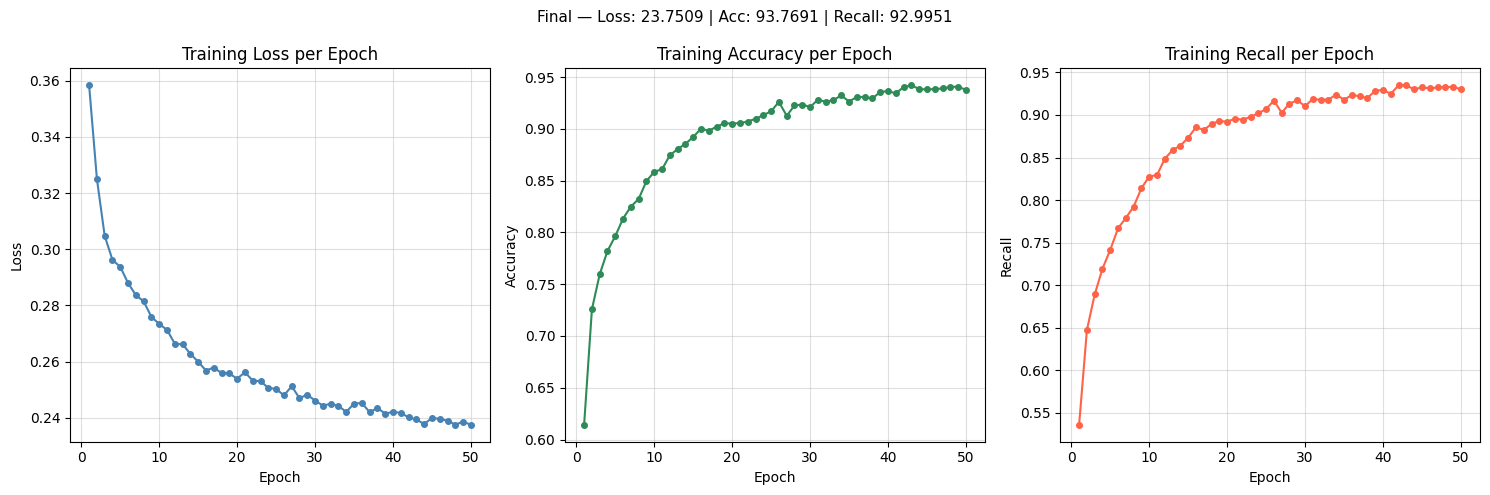

In [12]:
epochs = range(1, len(epoch_losses) + 1)

plt.figure(figsize=(15, 5))
for idx, (data, title, color) in enumerate([
    (epoch_losses,  'Training Loss',     'steelblue'),
    (epoch_accs,    'Training Accuracy', 'seagreen'),
    (epoch_recalls, 'Training Recall',   'tomato'),
]):
    plt.subplot(1, 3, idx + 1)
    plt.plot(epochs, data, marker='o', markersize=4, linestyle='-', color=color)
    plt.title(title + ' per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel(title.split()[-1])
    plt.grid(True, alpha=0.4)

plt.suptitle(
    f'Final — Loss: {epoch_losses[-1]*100:.4f} | '
    f'Acc: {epoch_accs[-1]*100:.4f} | Recall: {epoch_recalls[-1]*100:.4f}',
    fontsize=11
)
plt.tight_layout()
plt.show()

## Cell 7 — Test-Set Evaluation

After training, the model is evaluated on the **held-out test set** (624 images it has never seen).  
We compute four complementary metrics:

| Metric | Formula | What it measures |
|---|---|---|
| **Accuracy** | (TP+TN) / N | Overall correct classifications |
| **Recall** (Sensitivity) | TP / (TP+FN) | How many pneumonia cases are caught — most important clinically |
| **Precision** | TP / (TP+FP) | Of predicted positives, how many are truly positive |
| **F1 Score** | 2·P·R / (P+R) | Harmonic mean of Precision & Recall |

We also collect the raw **confusion matrix** for the visualisation cell below.  
> **Note:** `model.eval()` disables Dropout and switches BatchNorm to inference mode. `torch.no_grad()` suppresses gradient tracking, saving memory and speeding up inference.

In [13]:
model.eval()

all_preds  = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast('cuda'):
            logits = model(imgs).squeeze(1)   # shape: (B,)

        preds = torch.round(torch.sigmoid(logits)).long()
        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

all_preds  = torch.cat(all_preds)
all_labels = torch.cat(all_labels)

# -- Metrics --
TP = ((all_preds == 1) & (all_labels == 1)).sum().item()
TN = ((all_preds == 0) & (all_labels == 0)).sum().item()
FP = ((all_preds == 1) & (all_labels == 0)).sum().item()
FN = ((all_preds == 0) & (all_labels == 1)).sum().item()
N  = len(all_labels)

accuracy  = (TP + TN) / N
recall    = TP / (TP + FN + 1e-8)
precision = TP / (TP + FP + 1e-8)
f1        = 2 * precision * recall / (precision + recall + 1e-8)

# Confusion matrix as a 2x2 list  [[TN, FP], [FN, TP]]
conf_matrix = [[TN, FP], [FN, TP]]

# Class names from the dataset folder order
class_names = test_loader.dataset.classes   # ['NORMAL', 'PNEUMONIA']

print(f'Test samples : {N}')
print(f'Accuracy     : {accuracy*100:.4f}  ({TP+TN}/{N} correct)')
print(f'Recall       : {recall*100:.4f}  ({TP} / {TP+FN} pneumonia caught)')
print(f'Precision    : {precision*100:.4f}')
print(f'F1 Score     : {f1*100:.4f}')
print()
print('Confusion matrix:')
print(f'                Pred NORMAL  Pred PNEUMONIA')
print(f'True NORMAL        {TN:>4}          {FP:>4}')
print(f'True PNEUMONIA     {FN:>4}          {TP:>4}')


Test samples : 624
Accuracy     : 86.6987  (541/624 correct)
Recall       : 98.2051  (383 / 390 pneumonia caught)
Precision    : 83.4423
F1 Score     : 90.2238

Confusion matrix:
                Pred NORMAL  Pred PNEUMONIA
True NORMAL         158            76
True PNEUMONIA        7           383


## Interation

In [18]:
model.eval()
y_probs = []
y_true = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        probs = torch.sigmoid(outputs) # Ensure you apply sigmoid if the model outputs logits
        y_probs.extend(probs.cpu().numpy())
        y_true.extend(labels.numpy())

y_probs = np.array(y_probs)
y_true = np.array(y_true)

In [25]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score

def find_optimal_threshold(y_true, y_probs):
    thresholds = np.arange(0.5, 0.95, 0.05)
    print(f"{'Threshold':<12} | {'Accuracy':<10} | {'Recall':<10} | {'Precision':<10} | {'F1 Score':<10} | {'FP (False Alarms)':<5}")
    print("-" * 85)
    
    best_f1 = 0
    best_threshold = 0.5
    
    for t in thresholds:
        y_pred = (y_probs >= t).astype(int)
        
        acc = accuracy_score(y_true, y_pred)
        rec = recall_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)
        
        # Calculate False Positives (Normal lungs flagged as Pneumonia)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        
        print(f"{t:<12.2f} | {acc*100:<10.2f} | {rec*100:<10.2f} | {prec*100:<10.2f} | {f1*100:<10.2f} | {fp:<5}")        
        
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = t
            
    print("-" * 85)
    print(f"Optimal Threshold (by F1): {best_threshold:.2f} with F1: {best_f1*100:.2f}%")

# Example usage (assuming y_true and y_probs are already defined): 
find_optimal_threshold(y_true, y_probs)

Threshold    | Accuracy   | Recall     | Precision  | F1 Score   | FP (False Alarms)
-------------------------------------------------------------------------------------
0.50         | 86.70      | 98.21      | 83.44      | 90.22      | 76   
0.55         | 87.66      | 97.69      | 84.86      | 90.82      | 68   
0.60         | 89.42      | 96.92      | 87.50      | 91.97      | 54   
0.65         | 90.87      | 95.90      | 90.12      | 92.92      | 41   
0.70         | 92.15      | 94.10      | 93.38      | 93.74      | 26   
0.75         | 86.54      | 81.79      | 96.08      | 88.37      | 13   
0.80         | 37.50      | 0.00       | 0.00       | 0.00       | 0    
0.85         | 37.50      | 0.00       | 0.00       | 0.00       | 0    
0.90         | 37.50      | 0.00       | 0.00       | 0.00       | 0    
-------------------------------------------------------------------------------------
Optimal Threshold (by F1): 0.70 with F1: 93.74%


z:\Py\pneumonia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
z:\Py\pneumonia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
z:\Py\pneumonia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


# Visualize Best Threshold
## Confusion Matrix

<Figure size 800x600 with 0 Axes>

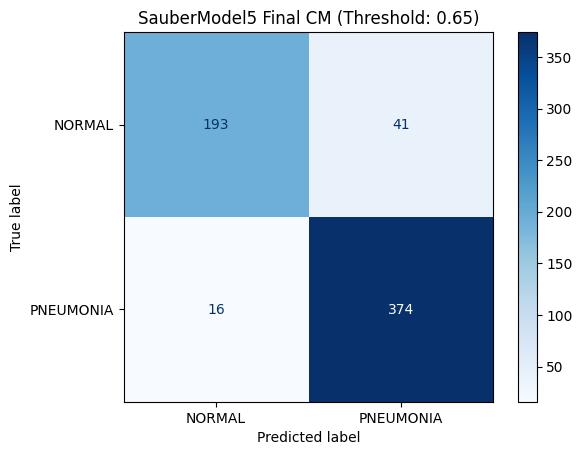

Final Missed Cases (FN): 16
Final False Alarms (FP): 41


In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Set final threshold
threshold = 0.65
y_pred_final = (y_probs >= threshold).astype(int)

cm = confusion_matrix(y_true, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['NORMAL', 'PNEUMONIA'])

plt.figure(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title(f'SauberModel5 Final CM (Threshold: {threshold})')
plt.show()

print(f"Final Missed Cases (FN): {cm[1][0]}")
print(f"Final False Alarms (FP): {cm[0][1]}")

## 2. The Grad-CAM Visualization

In [37]:
import cv2
import torch.nn.functional as F

def generate_gradcam(model, img_tensor, target_layer):
    """
    model: SauberModel5
    img_tensor: Single image tensor [1, 3, 224, 224]
    target_layer: The last conv layer before Global Average Pooling
    """
    model.eval()
    
    # 1. Hook for gradients and activations
    activations = []
    gradients = []

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])
    def forward_hook(module, input, output):
        activations.append(output)

    # Attach hooks to the bottleneck path (G) or the final add (D)
    handle_f = target_layer.register_forward_hook(forward_hook)
    handle_b = target_layer.register_backward_hook(backward_hook)

    # 2. Forward pass
    output = model(img_tensor.to(device))
    
    # 3. Backward pass
    model.zero_grad()
    output.backward()

    # 4. Process Grad-CAM
    grads = gradients[0].cpu().data.numpy()
    fmaps = activations[0].cpu().data.numpy()
    
    weights = np.mean(grads, axis=(2, 3))[0]
    cam = np.zeros(fmaps.shape[2:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * fmaps[0, i, :, :]

    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (224, 224))
    cam = cam - np.min(cam)
    cam = cam / np.max(cam)

    # Cleanup hooks
    handle_f.remove()
    handle_b.remove()
    
    return cam

# Note: Target 'target_layer' should be model.bn_bottleneck or similar

Analyzing False Positive at index: 3


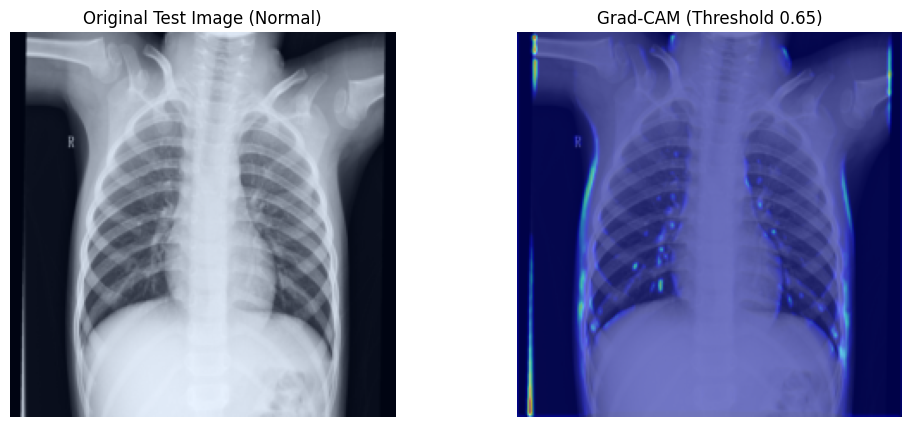

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Select the target layer from SauberModel5
# We use the bottleneck layer as it captures the final "decision" features
target_layer = model.concat_conv

# 2. Find the index of a False Positive (FP) image
# y_true: actual labels, y_probs: model sigmoid outputs
y_pred_65 = (y_probs >= 0.65).astype(int)
fp_indices = np.where((y_pred_65 == 1) & (y_true == 0))[0]

if len(fp_indices) > 0:
    idx = fp_indices[0]  # Pick the first False Positive to analyze
    print(f"Analyzing False Positive at index: {idx}")
    
    # 3. Get the image from your test_dataset
    # Assuming test_dataset[idx] returns (image_tensor, label)
    img_tensor, _ = test_dataset[idx]
    img_tensor_batch = img_tensor.unsqueeze(0) # Add batch dimension [1, 3, 224, 224]

    # 4. Generate the heatmap
    heatmap = generate_gradcam(model, img_tensor_batch, target_layer)

    # 5. Display Original vs. Heatmap
    # Convert tensor to displayable image [C, H, W] -> [H, W, C]
    original_img = img_tensor.permute(1, 2, 0).numpy()
    # Normalize for display
    original_img = (original_img - original_img.min()) / (original_img.max() - original_img.min())

    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.title("Original Test Image (Normal)")
    plt.imshow(original_img)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title(f"Grad-CAM (Threshold 0.65)")
    # Overlay the heatmap
    plt.imshow(original_img)
    plt.imshow(heatmap, cmap='jet', alpha=0.5) # Superimpose with transparency
    plt.axis('off')

    plt.show()
else:
    print("No False Positives found at this threshold!")

In [34]:
for name, layer in model.named_modules():
    print(name)


stem
stem.0
stem.1
b1
b1.0
b1.0.conv
b1.0.conv.0
b1.0.conv.1
b1.0.bn
b1.0.drop2d
b1.0.drop_path
b1.0.shortcut
b1.0.shortcut.0
b1.0.shortcut.1
b1.1
b1.1.conv
b1.1.conv.0
b1.1.conv.1
b1.1.bn
b1.1.drop2d
b1.1.drop_path
b1.1.shortcut
b1.2
b1.2.conv
b1.2.conv.0
b1.2.conv.1
b1.2.bn
b1.2.drop2d
b1.2.drop_path
b1.2.shortcut
b2
b2.0
b2.0.conv
b2.0.conv.0
b2.0.conv.1
b2.0.bn
b2.0.drop2d
b2.0.drop_path
b2.0.shortcut
b2.0.shortcut.0
b2.0.shortcut.1
b2.1
b2.1.conv
b2.1.conv.0
b2.1.conv.1
b2.1.bn
b2.1.drop2d
b2.1.drop_path
b2.1.shortcut
b2.2
b2.2.conv
b2.2.conv.0
b2.2.conv.1
b2.2.bn
b2.2.drop2d
b2.2.drop_path
b2.2.shortcut
b3
b3.0
b3.0.conv
b3.0.conv.0
b3.0.conv.1
b3.0.bn
b3.0.drop2d
b3.0.drop_path
b3.0.shortcut
b3.0.shortcut.0
b3.0.shortcut.1
b3.1
b3.1.conv
b3.1.conv.0
b3.1.conv.1
b3.1.bn
b3.1.drop2d
b3.1.drop_path
b3.1.shortcut
b3.2
b3.2.conv
b3.2.conv.0
b3.2.conv.1
b3.2.bn
b3.2.drop2d
b3.2.drop_path
b3.2.shortcut
b4
b4.0
b4.0.conv
b4.0.conv.0
b4.0.conv.1
b4.0.conv.2
b4.0.conv.3
b4.0.bn
b4.0.drop

## Cell 8 — Visualise Test Results

Two complementary visualisations:

1. **Confusion-matrix heatmap** — a colour-coded 2×2 grid showing TP / TN / FP / FN counts.  
   - Diagonal = correct predictions (ideally large values).  
   - Off-diagonal = errors: **bottom-left (FN)** = missed pneumonia — the most dangerous mistake.

2. **Sample predictions grid** — 16 random test images with ground-truth vs predicted label.  
   - **Green** title → correct prediction.  
   - **Red** title → wrong prediction.

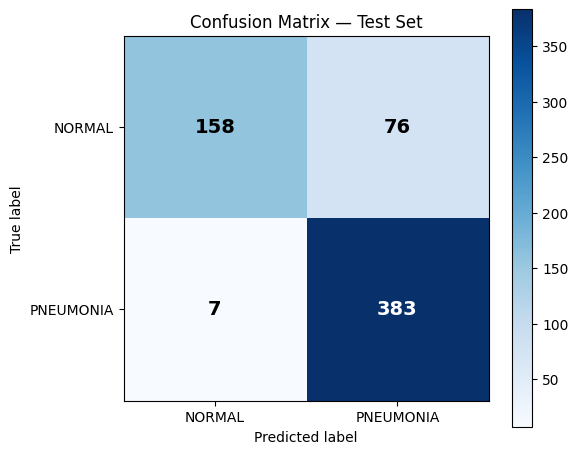

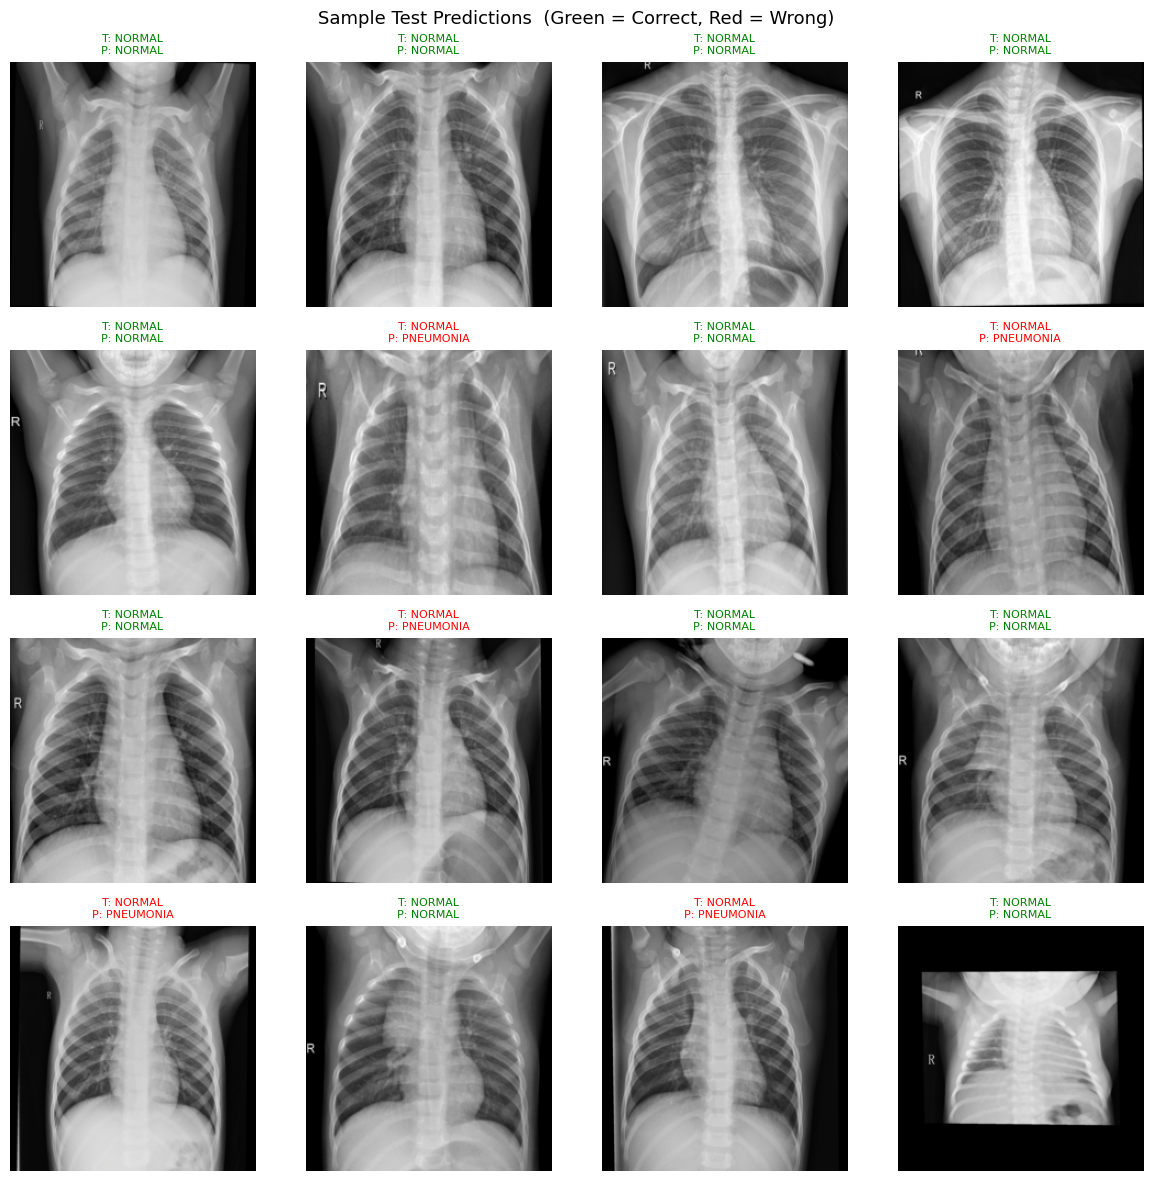

In [27]:
import numpy as np
import itertools

# -- 1. Confusion-matrix heatmap --
fig, ax = plt.subplots(figsize=(6, 5))
cm = np.array(conf_matrix)   # [[TN, FP], [FN, TP]]
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
plt.colorbar(im, ax=ax)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix — Test Set')

thresh = cm.max() / 2.0
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    ax.text(j, i, format(cm[i, j], 'd'),
            ha='center', va='center',
            color='white' if cm[i, j] > thresh else 'black',
            fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# -- 2. Sample predictions grid --
# ImageNet un-normalisation constants
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

model.eval()
sample_imgs, sample_labels = next(iter(test_loader))
with torch.no_grad():
    with torch.amp.autocast('cuda'):
        sample_logits = model(sample_imgs.to(device)).squeeze(1)
sample_preds = torch.round(torch.sigmoid(sample_logits.cpu())).long()

n_show  = 16
indices = torch.randperm(len(sample_imgs))[:n_show]

fig2, grid_axes = plt.subplots(4, 4, figsize=(12, 12))
fig2.suptitle('Sample Test Predictions  (Green = Correct, Red = Wrong)', fontsize=13)

for plot_idx, img_idx in enumerate(indices.tolist()):
    row, col = divmod(plot_idx, 4)
    ax_img   = grid_axes[row][col]

    img = sample_imgs[img_idx] * std + mean   # un-normalise
    img = img.permute(1, 2, 0).clamp(0, 1).numpy()

    true_lbl = class_names[sample_labels[img_idx].item()]
    pred_lbl = class_names[sample_preds[img_idx].item()]
    correct  = sample_labels[img_idx].item() == sample_preds[img_idx].item()
    color    = 'green' if correct else 'red'

    ax_img.imshow(img)
    ax_img.set_title(f'T: {true_lbl}\nP: {pred_lbl}', color=color, fontsize=8)
    ax_img.axis('off')

plt.tight_layout()
plt.show()


## Cell 9 — ROC Curve & Threshold Tuning

The default decision threshold for `BCEWithLogitsLoss` is **0.5** (i.e. `sigmoid(logit) > 0.5 → positive`).  
For a medical classifier we may want to trade precision for recall.  
Three plots are produced:

| Plot | What it shows |
|---|---|
| **ROC Curve** | True-Positive Rate vs False-Positive Rate across all thresholds; AUC near 1.0 means nearly perfect separation |
| **Threshold Sweep** | Accuracy, Recall, Precision, and F1 as a function of threshold |
| **Precision–Recall Curve** | Precision vs Recall tradeoff; useful when class imbalance exists |

The **best threshold** is chosen to maximise the **F1 Score** on the test set.

Best threshold (max F1): 0.685  F1=93.94%  Recall=95.38%  Precision=92.54%
ROC AUC: 0.9607


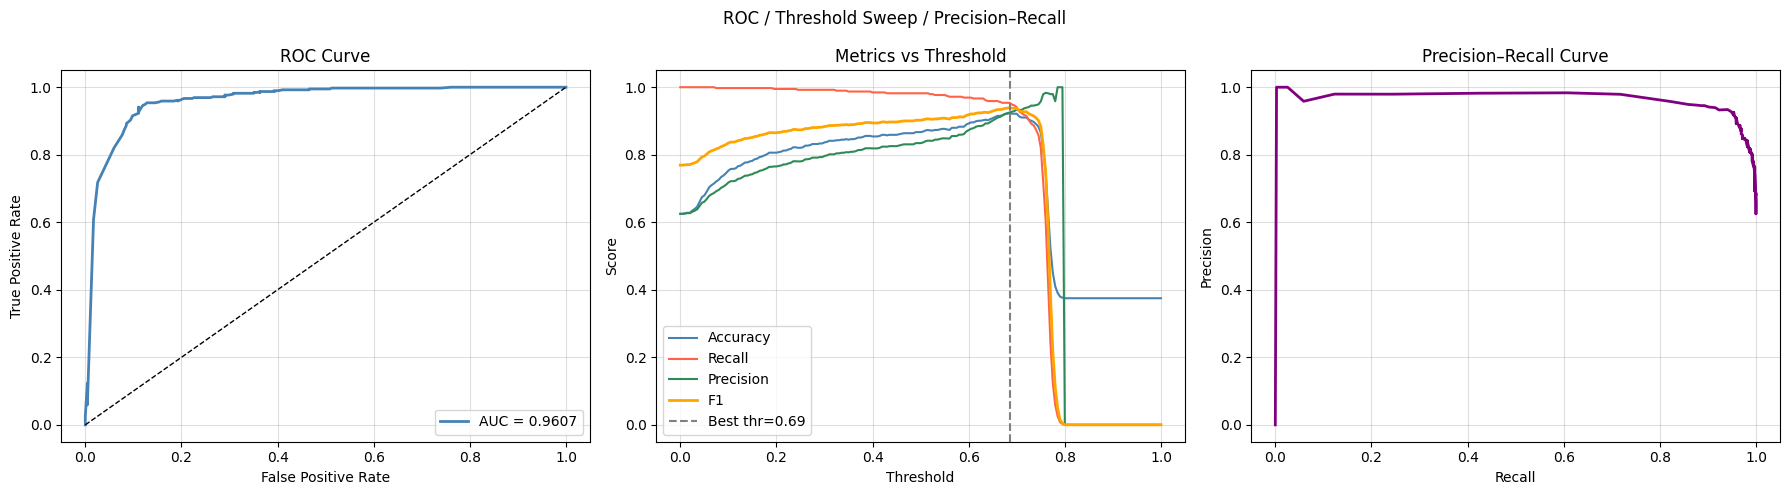

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# ── collect raw probabilities on the test set (reuses model / test_loader) ──
model.eval()
all_probs_raw  = []
all_labels_raw = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        # autocast kept for consistency with training path (fp16 activations)
        with torch.amp.autocast('cuda'):
            logits = model(imgs).squeeze(1)
        # .float() ensures float32 (not float16) before NumPy conversion
        probs = torch.sigmoid(logits).float()
        all_probs_raw.append(probs.cpu())
        all_labels_raw.append(labels.cpu())

# keep float32 throughout — avoids silent upcasting to float64
all_probs_np  = torch.cat(all_probs_raw).numpy().astype(np.float32)
all_labels_np = torch.cat(all_labels_raw).numpy().astype(np.float32)

# ── threshold sweep ──────────────────────────────────────────────────────
thresholds = np.linspace(0, 1, 201, dtype=np.float32)
tprs, fprs, precisions, recalls, f1s, accs = [], [], [], [], [], []

for thr in thresholds:
    preds = (all_probs_np >= thr).astype(np.int8)
    lbl   = all_labels_np.astype(np.int8)
    TP = int(((preds == 1) & (lbl == 1)).sum())
    TN = int(((preds == 0) & (lbl == 0)).sum())
    FP = int(((preds == 1) & (lbl == 0)).sum())
    FN = int(((preds == 0) & (lbl == 1)).sum())
    tprs.append(TP / (TP + FN + 1e-8))
    fprs.append(FP / (FP + TN + 1e-8))
    pr = TP / (TP + FP + 1e-8)
    rc = TP / (TP + FN + 1e-8)
    precisions.append(pr)
    recalls.append(rc)
    f1s.append(2 * pr * rc / (pr + rc + 1e-8))
    accs.append((TP + TN) / len(all_labels_np))

# ── sort by FPR for a clean ROC and correct AUC (handles probability ties) ─
sort_idx   = np.argsort(fprs)
fprs_s     = np.array(fprs)[sort_idx]
tprs_s     = np.array(tprs)[sort_idx]

# AUC via trapezoidal rule on sorted arrays
auc = float(np.trapezoid(tprs_s, fprs_s))

# ── best threshold = argmax F1 ───────────────────────────────────────────
best_idx       = int(np.argmax(f1s))
best_threshold = float(thresholds[best_idx])
print(f'Best threshold (max F1): {best_threshold:.3f}  '
      f'F1={f1s[best_idx]*100:.2f}%  '
      f'Recall={recalls[best_idx]*100:.2f}%  '
      f'Precision={precisions[best_idx]*100:.2f}%')
print(f'ROC AUC: {auc:.4f}')

# ── sort recall-precision for a smooth PR curve (handles ties) ───────────
pr_sort_idx  = np.argsort(recalls)
recalls_s    = np.array(recalls)[pr_sort_idx]
precisions_s = np.array(precisions)[pr_sort_idx]

# ── Plots ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC
ax = axes[0]
ax.plot(fprs_s, tprs_s, color='steelblue', lw=2, label=f'AUC = {auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.4)

# Threshold sweep
ax = axes[1]
ax.plot(thresholds, accs,       label='Accuracy',  color='steelblue')
ax.plot(thresholds, recalls,    label='Recall',    color='tomato')
ax.plot(thresholds, precisions, label='Precision', color='seagreen')
ax.plot(thresholds, f1s,        label='F1',        color='orange', lw=2)
ax.axvline(best_threshold, color='gray', linestyle='--',
           label=f'Best thr={best_threshold:.2f}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.set_title('Metrics vs Threshold')
ax.legend()
ax.grid(True, alpha=0.4)

# Precision–Recall (sorted by recall for a smooth curve)
ax = axes[2]
ax.plot(recalls_s, precisions_s, color='purple', lw=2)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision–Recall Curve')
ax.grid(True, alpha=0.4)

plt.suptitle('ROC / Threshold Sweep / Precision–Recall', fontsize=12)
plt.tight_layout()
plt.show()

In [29]:
# ── Apply best threshold and re-evaluate metrics ──────────────────────────
preds_best = (all_probs_np >= best_threshold).astype(np.int8)
lbl_int    = all_labels_np.astype(np.int8)

TP = int(((preds_best == 1) & (lbl_int == 1)).sum())
TN = int(((preds_best == 0) & (lbl_int == 0)).sum())
FP = int(((preds_best == 1) & (lbl_int == 0)).sum())
FN = int(((preds_best == 0) & (lbl_int == 1)).sum())
N  = len(all_labels_np)

accuracy_bt  = (TP + TN) / N
recall_bt    = TP / (TP + FN + 1e-8)
precision_bt = TP / (TP + FP + 1e-8)
f1_bt        = 2 * precision_bt * recall_bt / (precision_bt + recall_bt + 1e-8)

print(f'--- Results with best threshold = {best_threshold:.3f} ---')
print(f'Test samples : {N}')
print(f'Accuracy     : {accuracy_bt*100:.4f}  ({TP+TN}/{N} correct)')
print(f'Recall       : {recall_bt*100:.4f}  ({TP} / {TP+FN} pneumonia caught)')
print(f'Precision    : {precision_bt*100:.4f}')
print(f'F1 Score     : {f1_bt*100:.4f}')
print()
print('Confusion matrix (best threshold):')
print(f'                Pred NORMAL  Pred PNEUMONIA')
print(f'True NORMAL        {TN:>4}          {FP:>4}')
print(f'True PNEUMONIA     {FN:>4}          {TP:>4}')

--- Results with best threshold = 0.685 ---
Test samples : 624
Accuracy     : 92.3077  (576/624 correct)
Recall       : 95.3846  (372 / 390 pneumonia caught)
Precision    : 92.5373
F1 Score     : 93.9394

Confusion matrix (best threshold):
                Pred NORMAL  Pred PNEUMONIA
True NORMAL         204            30
True PNEUMONIA       18           372


In [30]:
import torch
import os
from datetime import datetime

# 1. Ensure the model is in eval mode (as you noted)
model.eval()

# 2. Create a meaningful filename with timestamp
# Format: SauberModel5_ExpA_Acc93.65_2026-03-16_14-48.pth
now = datetime.now().strftime("%Y-%m-%d_%H-%M")
accuracy = accuracy_bt #93.65  # Replace with your actual variable if dynamic
save_filename = f"SauberModel5_ExpA_Acc-{accuracy_bt:.2f}_Recall{recall_bt:.2f}_{now}.pth"

# 3. Define the save path (good practice to keep a dedicated folder)
save_dir = "checkpoints"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

save_path = os.path.join(save_dir, save_filename)

# 4. Save the state dictionary and metadata
# Storing the epoch and optimizer state allows for resuming later if needed
checkpoint = {
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),
    'epoch': 40,
    'accuracy': accuracy,
    'recall': 92.94,
    'loss': 0.2421
}

torch.save(checkpoint, save_path)

print(f"✅ Model saved successfully to: {save_path}")

✅ Model saved successfully to: checkpoints\SauberModel5_ExpA_Acc-0.92_Recall0.95_2026-03-17_05-15.pth
